In [ ]:
import os
import sys

# Проверяем, запущен ли ноутбук в среде Google Colab
if "google.colab" in sys.modules:
    !pip install uv -q
    !wget https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_11/pyproject.toml -q
    !uv pip install -r pyproject.toml --system -q
    os.kill(os.getpid(), 9)  # force runtime restart

# 11.2. N-BEATS: нелинейно, но интерпретируемо

DLinear раскладывал окно фиксированным скользящим средним и был линейным.
Вопрос: можно ли взять глубокую нелинейную сеть и всё равно получить прогноз, разложенный на понятные части?

**N-BEATS** (2019) — первая «чисто нейросетевая» модель, обошедшая победителя соревнования M4. Только полносвязные
слои, без рекуррентности и внимания.

[N-BEATS: Neural basis expansion analysis for interpretable time series forecasting](https://arxiv.org/abs/1905.10437)

**Контекст статьи.** На M4 (100 000 рядов, 2018) чистые ML-методы выступили плохо: шесть таких заявок заняли места
23, 37, 38, 48, 54 и 57 из 60. Победил гибрид S. Smyl — LSTM поверх экспоненциального сглаживания Хольта–Винтерса.
Организаторы сделали вывод, что будущее за гибридами и комбинациями статистических методов. Авторы N-BEATS
проверяют обратное: хватит ли «голой» глубокой сети без специфичных для рядов компонентов.

Ответ в статье (раздел 1.1, табл. 1): на M4 N-BEATS лучше статистического бенчмарка на 11% и победителя M4 — на 3%
(OWA 0.795 против 0.821). Отрыв от победителя (0.026) больше, чем отрыв победителя от второго места (0.017).
OWA — метрика M4: среднее отношений sMAPE и MASE модели к сезонному наивному прогнозу; у наивного OWA = 1.

Разбираем:
- устройство: блоки, backcast / forecast, двойные остаточные связи;
- generic- и интерпретируемую версии;
- разложение прогноза на тренд и сезонность и что на самом деле делает backcast;
- сравнение с официальным прогнозом системного оператора.

In [1]:
import logging
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from neuralforecast import NeuralForecast
from neuralforecast.models import NBEATS
from neuralforecast.tsdataset import TimeSeriesDataset
from statsforecast import StatsForecast
from statsforecast.models import SeasonalNaive
from utilsforecast.evaluation import evaluate
from utilsforecast.losses import mae, mape

warnings.simplefilter("ignore")
for name in ["pytorch_lightning", "lightning", "lightning.pytorch", "lightning_fabric"]:
    logging.getLogger(name).setLevel(logging.ERROR)
plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True

SEED = 1
ACCELERATOR = "gpu" if torch.cuda.is_available() else "cpu"
TRAINER_KW = dict(accelerator=ACCELERATOR, enable_progress_bar=False, enable_model_summary=False, logger=False)

OMP: Warning #179: Function Can't set size of /tmp file failed:


/Users/a.p.chikov/PycharmProjects/Временные ряды/Семинары/11/.venv/lib/python3.11/site-packages/joblib/_multiprocessing_helpers.py:44: UserWarning: [Errno 1] Operation not permitted.  joblib will operate in serial mode
  warnings.warn("%s.  joblib will operate in serial mode" % (e,))


In [2]:
def score(cv):
    """MAE и MAPE каждой модели, усреднённые по окнам кросс-валидации."""
    models = [c for c in cv.columns if c not in ("unique_id", "ds", "cutoff", "y")]
    res = evaluate(cv, metrics=[mae, mape], models=models)
    return res.groupby("metric")[models].mean().T.round({"mae": 0, "mape": 4}).sort_values("mae")


def n_params(model):
    return sum(p.numel() for p in model.parameters())

## Данные: потребление электроэнергии в Испании

Почасовое потребление (МВт) 2015–2018 и **официальный прогноз системного оператора** на сутки вперёд.
Время в исходнике со сдвигом +01/+02 (летнее время); переводим в UTC — получаем ровную часовую сетку.
36 пропусков интерполируем.

In [3]:
raw = pd.read_csv(
    "https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_11/data/energy_dataset.csv",
    usecols=["time", "total load actual", "total load forecast"],
)
energy = pd.DataFrame(
    {
        "unique_id": "Spain",
        "ds": pd.to_datetime(raw["time"], utc=True).dt.tz_localize(None),
        "y": raw["total load actual"].interpolate(),
        "tso": raw["total load forecast"],  # прогноз оператора
    }
)
print("пропусков было:", raw["total load actual"].isna().sum(), "| шаги сетки:", energy["ds"].diff().value_counts().to_dict())

пропусков было: 36 | шаги сетки: {Timedelta('0 days 01:00:00'): 35063}


Декабрь 2018 — праздники и «мосты»: в выходные 1–2 декабря потребление как в будни, в среду 5 декабря — как
в выходной, дальше Рождество. Модель, которая видит только историю ряда, о празднике узнать не может
(это задача экзогенных признаков, 11.4). Поэтому обрезаем ряд на 25 ноября: тест — пять обычных суток
со среды по воскресенье.

In [4]:
energy = energy[energy["ds"] < "2018-11-26"]
Y_df = energy[["unique_id", "ds", "y"]]
Y_df.tail()

,unique_id,ds,y
34196,Spain,2018-11-25 19:00:00,31182.0
34197,Spain,2018-11-25 20:00:00,31059.0
34198,Spain,2018-11-25 21:00:00,29672.0
34199,Spain,2018-11-25 22:00:00,27464.0
34200,Spain,2018-11-25 23:00:00,25151.0


Три сезонности: годовая (отопление и кондиционеры), недельная (будни / выходные) и суточная.

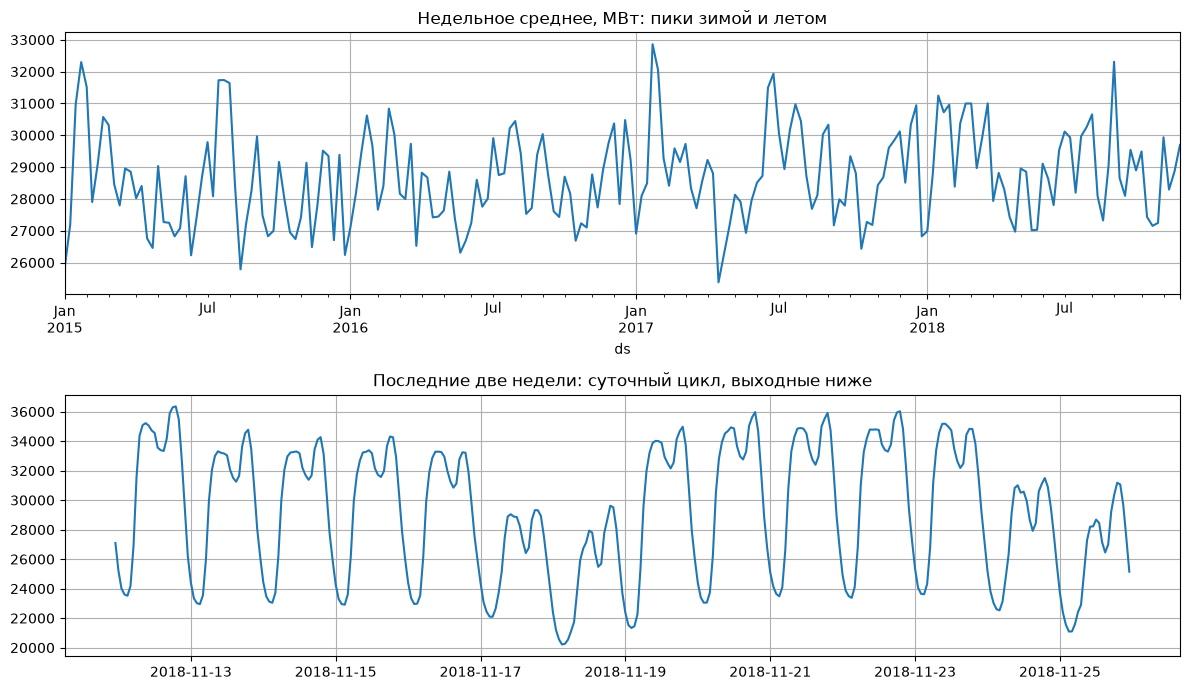

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
Y_df.set_index("ds")["y"].resample("W").mean().plot(ax=axes[0], title="Недельное среднее, МВт: пики зимой и летом")
two_weeks = Y_df[Y_df["ds"] >= Y_df["ds"].max() - pd.Timedelta(days=14)]
axes[1].plot(two_weeks["ds"], two_weeks["y"])
axes[1].set_title("Последние две недели: суточный цикл, выходные ниже")
fig.tight_layout()

## 1. Постановка

Прогноз на сутки вперёд (`h=24`) по неделе истории (`input_size=168`): в окне видна недельная структура.
Для N-BEATS рекомендуют окно в 2–7 горизонтов — у нас 7.

Формально: по окну $\mathbf{x} = [y_{T-L+1}, \dots, y_T] \in \mathbb{R}^L$ сеть сразу выдаёт вектор
$\hat{\mathbf{y}} = [\hat y_{T+1}, \dots, \hat y_{T+H}]$ — все $H$ шагов за один проход (прямой, не рекурсивный прогноз).
Длина окна в статье — гиперпараметр ансамбля: модели с окнами $2H, 3H, \dots, 7H$ обучаются отдельно и
усредняются (раздел 6).

Ряд один — модель **локальная** (в 11.1 была глобальная на 7 рядах).

In [6]:
H = 24
L = 7 * 24
N_WINDOWS = 5
MAX_STEPS = 1000
LR = 1e-3
common = dict(
    h=H, input_size=L, max_steps=MAX_STEPS, learning_rate=LR, scaler_type="standard", random_seed=SEED, **TRAINER_KW
)

## 2. Базовые модели и прогноз оператора

- `SeasonalNaive(24)` — те же часы вчера;
- `SeasonalNaive(168)` — те же часы неделю назад (учитывает будни / выходные);
- **оператор** — профессиональный прогноз: погода, календарь, опыт диспетчеров. Наши модели видят только историю.

In [7]:
sf = StatsForecast(
    models=[SeasonalNaive(24, alias="SeasonalNaive(24)"), SeasonalNaive(168, alias="SeasonalNaive(168)")], freq="h"
)
cv_all = sf.cross_validation(df=Y_df, h=H, n_windows=N_WINDOWS, step_size=H)
cv_all = cv_all.merge(energy[["ds", "tso"]].rename(columns={"tso": "Оператор"}), on="ds")
cutoffs = cv_all["cutoff"].unique()
print("прогнозируемые сутки:", [pd.Timestamp(c + pd.Timedelta(hours=1)).strftime("%a %d.%m") for c in cutoffs])
score(cv_all)

прогнозируемые сутки: ['Wed 21.11', 'Thu 22.11', 'Fri 23.11', 'Sat 24.11', 'Sun 25.11']


metric,mae,mape
Оператор,201.0,0.0071
SeasonalNaive(24),1184.0,0.0428
SeasonalNaive(168),1296.0,0.0433


## 3. Как устроен N-BEATS

![N-BEATS](../pic/N-beast.png)

**Блок.** Полносвязная сеть получает окно и выдаёт коэффициенты $\theta$. Из них линейно, через **базис**,
получаются два выхода:
- **backcast** — приближение собственного входа («что из истории я объяснил»);
- **forecast** — вклад блока в прогноз.

В формулах (блок $\ell$, раздел 3.1 статьи): четыре слоя FC + ReLU, затем две линейные «головы»

$$\mathbf{h}_\ell = \mathrm{FC}_4(\mathrm{FC}_3(\mathrm{FC}_2(\mathrm{FC}_1(\mathbf{x}_\ell)))), \qquad
\theta^f_\ell = \mathbf{W}^f_\ell \mathbf{h}_\ell, \qquad \theta^b_\ell = \mathbf{W}^b_\ell \mathbf{h}_\ell,$$

$$\hat{\mathbf{y}}_\ell = \sum_i \theta^f_{\ell,i}\, \mathbf{v}^f_i, \qquad
\hat{\mathbf{x}}_\ell = \sum_i \theta^b_{\ell,i}\, \mathbf{v}^b_i.$$

Векторы $\mathbf{v}_i$ — базис («формы волн» длины $H$ или $L$), $\theta$ — коэффициенты разложения по нему.
Отсюда название: *neural basis expansion* — сеть предсказывает не сами значения, а коэффициенты при базисных функциях.

**Двойные остаточные связи** (*doubly residual stacking*, раздел 3.2). Следующий блок получает не окно, а остаток:
окно минус backcast предыдущего. Прогнозы блоков складываются:

$$\mathbf{x}_{\ell} = \mathbf{x}_{\ell-1} - \hat{\mathbf{x}}_{\ell-1}, \qquad \hat{\mathbf{y}} = \sum_\ell \hat{\mathbf{y}}_\ell.$$

Каждый блок вычитает то, что сумел объяснить, и следующий работает с тем, что осталось — как при
последовательном удалении тренда и сезонности. Две «остаточные» ветки: по входу (backcast) и по выходу (forecast).
Вторая и даёт интерпретируемость: прогноз — сумма частичных прогнозов, и их можно смотреть по отдельности.

**Стек** — несколько блоков подряд с базисом одного типа. Две версии:

| | базис | что получаем |
|---|---|---|
| generic | обучаемый (`"identity"`) | только точность |
| интерпретируемая | тренд — полиномы низкой степени, сезонность — гармоники Фурье | прогноз = тренд + сезонность |

- **Generic:** $\hat{\mathbf{y}}_\ell = \mathbf{V}^f_\ell \theta^f_\ell + \mathbf{b}^f_\ell$, матрица $\mathbf{V}^f_\ell$
  обучается. Её столбцы — тоже формы волн, но, как пишут авторы, никакой структуры в них не видно.
- **Тренд:** $\hat{\mathbf{y}}_{s,\ell} = \mathbf{T}\theta^f_{s,\ell}$, где $\mathbf{T} = [\mathbf{1}, \mathbf{t}, \dots, \mathbf{t}^p]$,
  $\mathbf{t} = [0, 1, \dots, H-1]/H$. При малой степени $p$ (в статье $p=2$) получается только плавная кривая.
- **Сезонность:** $\hat{\mathbf{y}}_{s,\ell} = \mathbf{S}\theta^f_{s,\ell}$, где
  $\mathbf{S} = [\mathbf{1}, \cos(2\pi\mathbf{t}), \dots, \sin(2\pi\mathbf{t}), \dots]$ — ряд Фурье: только периодические формы.

Базисы $\mathbf{T}$ и $\mathbf{S}$ фиксированы, обучается лишь MLP, выдающий коэффициенты. Ограничение на форму выхода
и есть встроенное предположение модели (*inductive bias*): стек тренда физически не может нарисовать суточный цикл.

В статье интерпретируемая версия — 2 стека по 3 блока, веса общие внутри стека: сначала тренд, потом
сезонность. Тренд вычитается из окна до того, как его увидит стек сезонности.

**Что показали абляции (приложение B статьи, M4):**
- **Глубина помогает.** Generic с 1 стеком — sMAPE 11.154, с 30 стеками — 10.937 (табл. 5). 30 стеков по 5 слоёв —
  сеть глубиной 150 слоёв, и она обучается без проблем благодаря остаточным связям.
- **Тренд и сезонность дополняют друг друга** (табл. 6): только сезонность — 11.189, только тренд — 11.572,
  1 + 1 блок — 11.040, 3 + 3 блока — 10.986. Стеки разных типов вместе лучше, чем стеки одного типа.
- **Обе остаточные ветки нужны** (табл. 7, ансамбль 18 generic-моделей): полная N-BEATS — sMAPE 11.251, без
  вычитания backcast (все блоки видят исходное окно) — 11.538, без обеих веток (обычная глубокая MLP) — 13.931.
- **Общие веса:** интерпретируемой версии помогает делить веса внутри стека, generic-версии — нет (приложение D).

**Взгляд авторов (раздел 6): метаобучение.** Блоки можно читать как шаги «внутреннего» алгоритма: каждый уточняет
прогноз по конкретному окну, а веса сети — «внешний» алгоритм, выученный на всех окнах. Больше блоков — больше
шагов уточнения; это согласуется с тем, что добавление блоков улучшает качество.

## 4. Generic N-BEATS

3 стека по 1 блоку (как по умолчанию в `neuralforecast`), во всех трёх — обучаемый базис `"identity"`.
(По умолчанию библиотека собирает смешанную модель `["identity", "trend", "seasonality"]`.)

Отличия от статьи, о которых стоит помнить:
- в статье generic — **30 стеков** по 1 блоку из 4 слоёв шириной 512, без общих весов (табл. 18); у нас 3 стека;
- в статье функция потерь — sMAPE, MAPE или MASE (модели с разными потерями входят в ансамбль), у нас MAE;
- в `neuralforecast` прогноз стартует с последнего значения окна (наивный прогноз), блоки добавляют к нему
  поправки. В статье такого слагаемого нет, это деталь реализации.

In [8]:
generic = NBEATS(stack_types=["identity", "identity", "identity"], alias="N-BEATS generic", **common)
nf_generic = NeuralForecast(models=[generic], freq="h")
start = time.time()
cv_generic = nf_generic.cross_validation(df=Y_df, n_windows=N_WINDOWS, step_size=H)
print(f"обучение + прогноз: {time.time() - start:.0f} с, параметров: {n_params(nf_generic.models[0]) / 1e6:.2f} млн")
cv_all = cv_all.merge(cv_generic.drop(columns="y"), on=["unique_id", "ds", "cutoff"])
score(cv_all)

обучение + прогноз: 73 с, параметров: 2.92 млн


metric,mae,mape
Оператор,201.0,0.0071
N-BEATS generic,277.0,0.0094
SeasonalNaive(24),1184.0,0.0428
SeasonalNaive(168),1296.0,0.0433


## 5. Интерпретируемый N-BEATS

`stack_types=["trend", "seasonality"]`, по 3 блока, `shared_weights=True` — как в статье (три блока стека
используют одни и те же веса MLP).

Ширина слоёв у нас 512 в обоих стеках. В статье стеки несимметричны (табл. 18): у тренда ширина 256,
у сезонности — 2048. Плавной кривой нужно мало коэффициентов, а форма сезонности сложнее.

Обучаем один раз на истории до первого `cutoff` (так же делает `cross_validation`), а прогнозы строим руками:
на каждом окне понадобятся не только прогноз, но и его компоненты.

In [9]:
interp = NBEATS(
    stack_types=["trend", "seasonality"],
    n_blocks=[3, 3],
    mlp_units=2 * [[512, 512]],
    shared_weights=True,
    alias="N-BEATS interpretable",
    **common,
)
nf_interp = NeuralForecast(models=[interp], freq="h")
start = time.time()
nf_interp.fit(df=Y_df[Y_df["ds"] <= cutoffs[0]])
model = nf_interp.models[0]
print(f"обучение: {time.time() - start:.0f} с, параметров: {n_params(model) / 1e6:.2f} млн")

обучение: 105 с, параметров: 1.28 млн


Базисы, которые использует модель: стек тренда умеет рисовать только плавные кривые,
стек сезонности — только суммы синусоид с периодом не длиннее горизонта.

Детали реализации:
- тренд: `n_basis=2` даёт полиномы $1, t, t^2$ — степень $p=2$, как в статье;
- сезонность: в статье частоты целые, $0, 1, \dots, \lfloor H/2 - 1 \rfloor$ колебаний за горизонт. В `neuralforecast`
  шаг частоты равен `1/n_harmonics`: при `n_harmonics=2` это $0, 1, 1.5, 2, \dots, 11.5$ колебаний за 24 часа
  (периоды 24, 16, 12, 9.6… ч). Вместе с косинусами и синусами — 46 функций. Суточный цикл — частота 1.

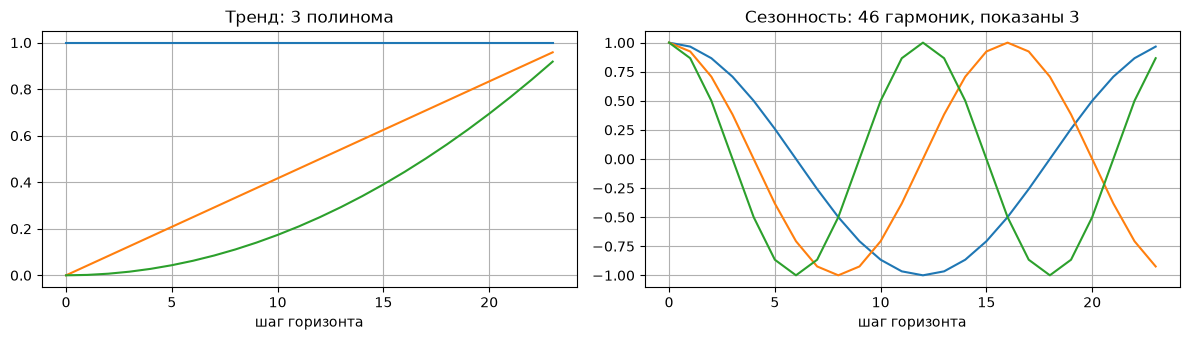

In [10]:
trend_basis = model.blocks[0].basis.forecast_basis.cpu().numpy()  # (функции, H)
seas_basis = model.blocks[3].basis.forecast_basis.cpu().numpy()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(trend_basis.T)
axes[0].set_title(f"Тренд: {len(trend_basis)} полинома")
axes[1].plot(seas_basis[[1, 2, 3]].T)
axes[1].set_title(f"Сезонность: {len(seas_basis)} гармоник, показаны 3")
for ax in axes:
    ax.set_xlabel("шаг горизонта")
fig.tight_layout()

### Прогноз и разложение

`decompose` возвращает вклад каждого блока: первая строка — уровень (последнее значение окна, с него начинается
сумма), дальше 3 блока тренда и 3 блока сезонности.

Тонкость: с `scaler_type="standard"` модель работает с нормированным окном, и каждый вклад возвращается в МВт
по отдельности — к каждому прибавлено среднее окна $\bar y$. Чтобы компоненты складывались, вычитаем $\bar y$
из вкладов блоков. Проверим, что уровень + тренд + сезонность совпадают с обычным `predict`.

In [11]:
def forecast_components(cutoff):
    hist = Y_df[Y_df["ds"] <= cutoff]
    dataset, *_ = TimeSeriesDataset.from_df(hist)
    blocks = model.decompose(dataset=dataset)[-1]  # (1 + 6 блоков, H)
    window_mean = hist["y"].to_numpy()[-L:].mean()
    comp = pd.DataFrame(
        {
            "unique_id": "Spain",
            "ds": pd.date_range(cutoff, periods=H + 1, freq="h")[1:],
            "cutoff": cutoff,
            "уровень": blocks[0],
            "тренд": (blocks[1:4] - window_mean).sum(axis=0),
            "сезонность": (blocks[4:7] - window_mean).sum(axis=0),
        }
    )
    comp["N-BEATS interpretable"] = comp[["уровень", "тренд", "сезонность"]].sum(axis=1)
    forecast = nf_interp.predict(df=hist)["N-BEATS interpretable"].to_numpy()
    assert np.allclose(comp["N-BEATS interpretable"], forecast, atol=0.1), "разложение не сходится с прогнозом"
    return comp


components = pd.concat([forecast_components(c) for c in cutoffs])
print("сумма компонент совпадает с predict на всех окнах")
cv_all = cv_all.merge(
    components[["unique_id", "ds", "cutoff", "N-BEATS interpretable"]], on=["unique_id", "ds", "cutoff"]
)
score(cv_all)

сумма компонент совпадает с predict на всех окнах


metric,mae,mape
Оператор,201.0,0.0071
N-BEATS interpretable,259.0,0.0089
N-BEATS generic,277.0,0.0094
SeasonalNaive(24),1184.0,0.0428
SeasonalNaive(168),1296.0,0.0433


Обе версии N-BEATS сильно лучше сезонных наивных и близки к прогнозу оператора, хотя видят только
неделю истории — без погоды и календаря. Интерпретируемость почти ничего не стоит по качеству,
а параметров у интерпретируемой версии более чем вдвое меньше.

Разница между двумя версиями N-BEATS на пяти сутках — в пределах того, что даёт смена `random_seed`.
Делать выводы по третьему знаку на одном запуске нельзя.

**Что в статье.** Та же картина на больших бенчмарках (табл. 1): на M4 OWA у generic 0.797, у интерпретируемой 0.798,
у их общего ансамбля 0.795. На TOURISM generic заметнее лучше (MAPE 18.47 против 18.97). Ограничение базисом
стоит мало, но не ноль.

Близкий к нашему пример — датасет ELECTRICITY (почасовое потребление электроэнергии, приложение C.4, табл. 16).
На разбиении из статьи DeepAR N-BEATS-G получает ND 0.064 против 0.07 у DeepAR
(ND $= \sum|\hat y - y| / \sum|y|$, по сути MAE в долях от среднего). При этом, в отличие от моделей Amazon, он не использует признаков
вроде часа суток и дня недели. Календарную структуру модель извлекает из самого окна истории — как и у нас.

### Что внутри прогноза

Будний день и воскресенье: прогноз = уровень (последнее значение) + тренд + сезонность.

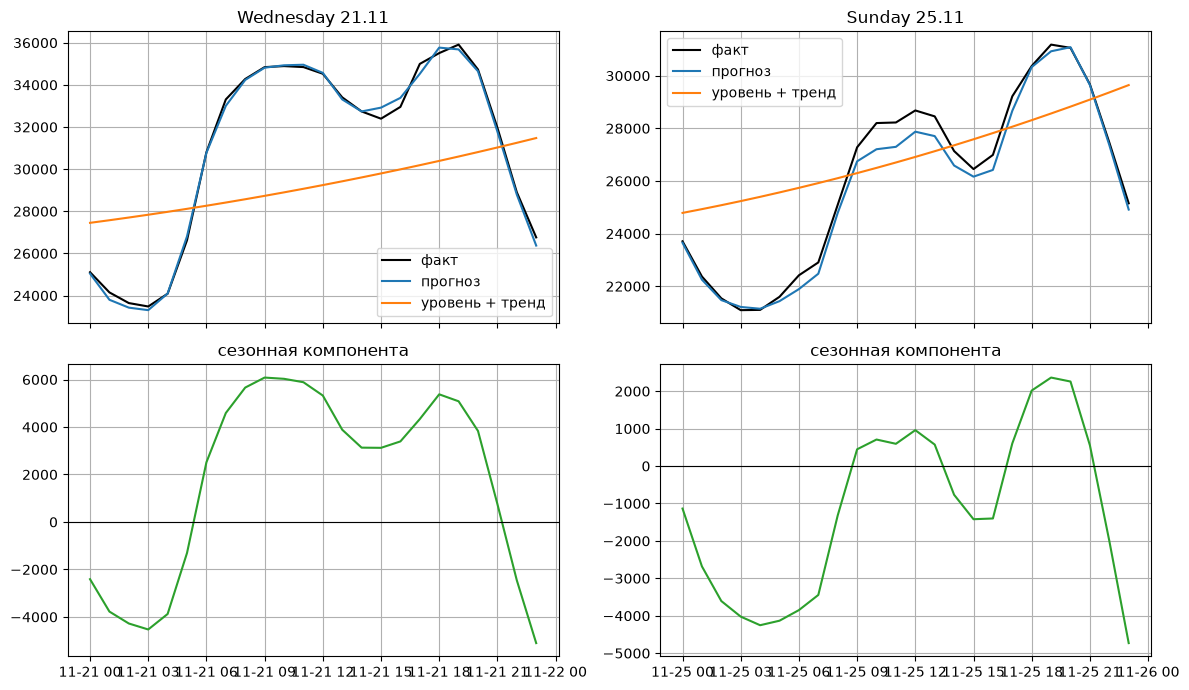

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex="col")
for col, cutoff in enumerate([cutoffs[0], cutoffs[-1]]):
    comp = components[components["cutoff"] == cutoff]
    fact = cv_all[cv_all["cutoff"] == cutoff]
    day = pd.Timestamp(cutoff + pd.Timedelta(hours=1)).strftime("%A %d.%m")
    axes[0, col].plot(fact["ds"], fact["y"], color="black", label="факт")
    axes[0, col].plot(comp["ds"], comp["N-BEATS interpretable"], label="прогноз")
    axes[0, col].plot(comp["ds"], comp["уровень"] + comp["тренд"], label="уровень + тренд")
    axes[0, col].set_title(day)
    axes[0, col].legend()
    axes[1, col].plot(comp["ds"], comp["сезонность"], color="tab:green")
    axes[1, col].axhline(0, color="black", lw=0.8)
    axes[1, col].set_title("сезонная компонента")
fig.tight_layout()

- **Уровень + тренд** — плавная кривая от последнего наблюдённого значения (полночь, ночной минимум).
  Это медленная составляющая внутри суток, а не «средний уровень дня».
- **Сезонность** — суточная форма. В среду — высокое дневное плато, амплитуда около ±6000 МВт.
  В воскресенье амплитуда втрое меньше и нет рабочего плато: модель по неделе истории поняла, что это выходной.

Та же логика, что у классической декомпозиции (неделя 6), только разложение выучено сквозным обучением и сразу
продолжено на горизонт. И, как там, разложение не единственно: часть подъёма можно отнести и к тренду, и к
сезонности — граница задаётся базисами.

**В статье (рис. 2, приложение E)** то же сравнение сделано на рядах M4 разной частоты. Выходы двух стеков
generic-модели произвольны: тренд и сезонность могут оказаться в обоих. У интерпретируемой модели тренд монотонный
и медленный, сезонность — регулярная. Её размах велик, только если сезонность в ряде действительно есть, а размах
тренда мал, если тренда нет. При этом итоговые прогнозы двух версий почти совпадают, хотя компоненты сильно
различаются: одну и ту же сумму можно разложить по-разному.

### Backcast: что блоки вычитают из окна

Остаётся вторая ветка — backcast. Пройдём по блокам обученной модели вручную, повторяя `forward` из
`neuralforecast`: нормируем окно (как `scaler_type="standard"`), подаём его в блоки, вычитаем backcast и
накапливаем прогноз. Сумма уровня и прогнозов блоков должна совпасть с уже посчитанным прогнозом. Попутно
смотрим, сколько от окна остаётся после каждого блока (стандартное отклонение остатка).

расхождение с прогнозом модели: 0.004 МВт
std остатка: вход 1.00 | после блоков тренда 1.00 1.00 1.00 | после блоков сезонности 0.78 0.77 0.79


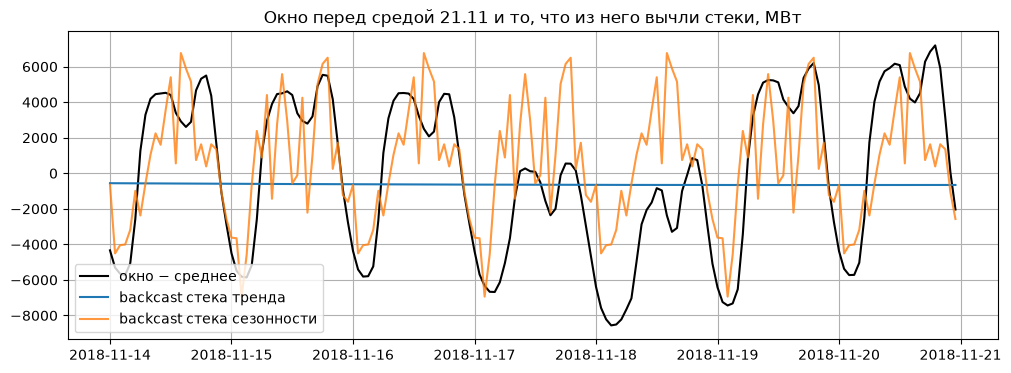

In [13]:
cutoff = cutoffs[0]
window = Y_df.loc[Y_df["ds"] <= cutoff, "y"].to_numpy()[-L:]
mu, sd = window.mean(), window.std()
residual = torch.tensor((window - mu) / sd, dtype=torch.float32)[None].flip(-1)  # блоки читают окно с конца
forecast = torch.zeros(1, H)
backcasts, residual_std = [], [residual.std().item()]
with torch.no_grad():
    for block in model.blocks:
        backcast, block_forecast = block(residual)
        residual = residual - backcast
        forecast = forecast + block_forecast[..., 0]
        backcasts.append(backcast.flip(-1)[0].numpy() * sd)
        residual_std.append(residual.std().item())

manual = window[-1] + forecast[0].numpy() * sd  # уровень + поправки блоков, в МВт
expected = components.loc[components["cutoff"] == cutoff, "N-BEATS interpretable"].to_numpy()
print(f"расхождение с прогнозом модели: {np.abs(manual - expected).max():.3f} МВт")
print("std остатка: вход", *[f"{s:.2f}" for s in residual_std[:1]], "| после блоков тренда",
      *[f"{s:.2f}" for s in residual_std[1:4]], "| после блоков сезонности", *[f"{s:.2f}" for s in residual_std[4:]])

window_ds = Y_df.loc[Y_df["ds"] <= cutoff, "ds"].iloc[-L:]
fig, ax = plt.subplots()
ax.plot(window_ds, window - mu, color="black", label="окно − среднее")
ax.plot(window_ds, sum(backcasts[:3]), label="backcast стека тренда")
ax.plot(window_ds, sum(backcasts[3:]), label="backcast стека сезонности", alpha=0.8)
ax.set_title("Окно перед средой 21.11 и то, что из него вычли стеки, МВт")
ax.legend(loc="lower left");

Ручной проход совпал с моделью — значит, формулы двойных остаточных связей выше и есть весь `forward`.

Неожиданное: backcast **не восстанавливает окно**. Стек тренда почти ничего не вычитает, стек сезонности
снимает лишь часть суточного цикла и добавляет зубцы, а остаток после всех блоков по размаху сравним со входом.

Это не ошибка. Функция потерь смотрит только на прогноз, на backcast отдельного штрафа нет. Он обучается лишь
через то, как помогает следующим блокам. В статье цель backcast так и описана: убрать из входа то, что
мешает прогнозу следующих блоков, а не реконструировать историю. Поэтому интерпретировать стоит
forecast-компоненты, а не backcast.

## 6. Для самостоятельного изучения

- **Ансамбль.** В статье N-BEATS — это медиана 180 моделей (раздел 3.4). Разнообразие берётся из трёх источников:
  функция потерь (sMAPE, MASE, MAPE), длина окна ($2H, 3H, \dots, 7H$) и случайная инициализация с бэггингом.
  Обучите 3 модели с разными `random_seed` и сравните разброс их ошибок с разницей между generic и interpretable.
- **Гиперпараметры интерпретируемой версии:** `n_harmonics`, `n_basis`, `n_blocks`, `shared_weights`.
- **`h=168`.** Прогноз на неделю: в сезонной компоненте появится недельная структура.
- **Праздники.** Уберите обрезку на 25 ноября и посмотрите на ошибку в декабрьские праздники.

In [14]:
nf_seeds = NeuralForecast(
    models=[
        NBEATS(stack_types=["identity", "identity", "identity"], alias=f"generic seed={s}", **{**common, "random_seed": s})
        for s in [1, 2, 3]
    ],
    freq="h",
)
cv_seeds = nf_seeds.cross_validation(df=Y_df, n_windows=N_WINDOWS, step_size=H)
cv_seeds["медиана 3 сидов"] = cv_seeds[[f"generic seed={s}" for s in [1, 2, 3]]].median(axis=1)
score(cv_seeds)

metric,mae,mape
медиана 3 сидов,234.0,0.0079
generic seed=3,245.0,0.0082
generic seed=2,273.0,0.0092
generic seed=1,277.0,0.0094


Разброс между сидами сопоставим с разницей generic / interpretable, а медиана трёх моделей лучше любой
из них по отдельности. Поэтому в статье ансамбль — не украшение, а часть метода.

Два замечания из статьи про ансамбль:
- **Ансамбль вместо регуляризации.** Dropout и L2 улучшали отдельные модели, но ухудшали ансамбль (раздел 3.4).
  Ансамблю нужно разнообразие моделей, а регуляризация делает их похожими.
- **180 моделей не обязательны.** На M4 ансамбль из 18 моделей теряет меньше 0.5% по OWA: 0.802 против 0.797
  у 180 (рис. 3). Ансамбль в 10 раз меньше почти не уступает полному.

## 7. Итоги

| | DLinear | N-BEATS generic | N-BEATS interpretable |
|---|---|---|---|
| нелинейность | нет | MLP в каждом блоке | MLP в каждом блоке |
| разложение | фиксированное (скользящее среднее) | неявное | выученное: тренд + сезонность |
| базис | — | обучаемый | полиномы + гармоники Фурье |
| главные параметры | `input_size`, `moving_avg_window` | `stack_types`, `n_blocks`, `mlp_units` | + `n_basis`, `n_harmonics`, `shared_weights` |

Главное:
- N-BEATS предсказывает коэффициенты разложения по базису; прогноз — сумма частичных прогнозов блоков,
  каждый блок работает с остатком окна после предыдущих.
- Фиксированный базис (полиномы + Фурье) делает компоненты прогноза интерпретируемыми и почти не стоит точности —
  и в статье (OWA 0.798 против 0.797 на M4), и у нас.
- Backcast — вспомогательный сигнал для следующих блоков, а не реконструкция истории.
- Без признаков календаря модель по неделе истории различает будни и выходные.
- В статье результат достигается ансамблем (медиана 180 моделей); у нас даже медиана трёх сидов заметно лучше
  одной модели.

Ограничение N-BEATS: каждый блок выдаёт все `h` точек горизонта в полном разрешении. На горизонте в сотни
точек число параметров растёт, а прогноз начинает подгоняться под шум. Как с этим справляется N-HiTS — в 11.3.